# Toy example

In [26]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import torch
import deepinv as dinv
from deepinv.physics import Denoising, GaussianNoise, PoissonNoise
from deepinv.utils.demo import load_url_image, get_image_url
from deepinv.utils.plotting import plot
from deepinv.loss.metric import SSIM, PSNR

from opt_functions.plot_results import *
from opt_functions.Solver_functions.white_opt_pnp import *
        
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

import matplotlib.pyplot as plt

from huggingface_hub import hf_hub_download

from microssim import MicroSSIM, micro_structural_similarity
from skimage.metrics import structural_similarity


In [17]:
x_true.device

device(type='cpu')

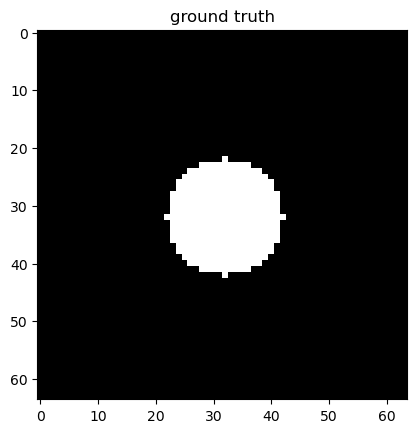

In [69]:
N = 64        # image size
R = 10        # disk radius (pixels)

yy, xx = torch.meshgrid(torch.arange(N), torch.arange(N), indexing="ij")
x_true = (((yy - N / 2) ** 2 + (xx - N / 2) ** 2) <= R ** 2).float()
x_true = x_true[None, None].to(device)          # shape (1, 1, N, N), as deepinv expects

plt.imshow(x_true.cpu().squeeze(), cmap="gray")
plt.title("ground truth")
plt.show()

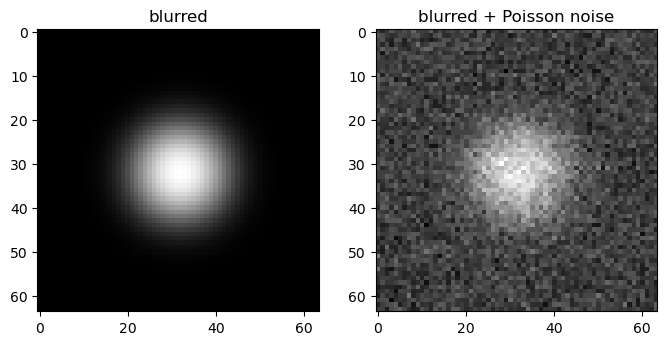

In [70]:
flux = 20.0
bkg = 1.0

# Blur with Gaussian filter parameter
filter = dinv.physics.blur.gaussian_blur(sigma=(5, 5))

physics = dinv.physics.BlurFFT(x_true.shape[1:], filter=filter, device=device)
physics.noise_model = dinv.physics.GaussianNoise(sigma=0.1)

# Simulate measurements

y = physics(x_true)         # noisy measurement (photon counts)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(physics.A(x_true).cpu().squeeze(), cmap="gray"); ax[0].set_title("blurred")
ax[1].imshow(y.cpu().squeeze(), cmap="gray");         ax[1].set_title("blurred + Poisson noise")
plt.show()

In [71]:
eps = 0.1
tv = dinv.optim.TVPrior()            # we only use its finite differences: tv.nabla
drunet = dinv.models.DRUNet(in_channels=1, out_channels=1,
                            pretrained="download", device=device)

def data_fidelity(kind):
    if kind == "L2":
        return dinv.optim.L2()
    if kind == "KL":
        return dinv.optim.PoissonLikelihood()

def regularizer(kind):
    if kind == "L1":
        return dinv.optim.L1Prior()
    if kind == "TV":
        return dinv.optim.TVPrior()
    if kind == "Drunet":
        return dinv.optim.PnP(denoiser=drunet)

In [72]:
FIDELITY = "KL"       # "L2" or "KL"
REG      = "Drunet"   # "L1", "TV" or "Drunet"
lam      = 1.0
n_iter   = 500

L_R = {"L1": 1 / eps, "TV": 8 / eps, "Drunet": 2.0}[REG]
step = 1 / (flux ** 2 + lam * L_R) if FIDELITY == "L2" else 1e-3
print(f"{FIDELITY} + {REG}, lam = {lam}, step = {step:.2e}")

x = torch.full_like(x_true, 0.5)     # start from a gray image
cost = []

model = dinv.optim.optim_builder(
    iteration="PGD",
    prior=regularizer(REG),
    data_fidelity=data_fidelity(FIDELITY),
    params_algo={"stepsize": step, "lambda": lam, "g_param": 0.5},
    max_iter=n_iter,
    early_stop=False,
    custom_init=lambda y, physics: {"est": ((physics.A_adjoint(y) / flux ** 2).clamp(min=0),)},
)

x_rec, metrics = model(y, physics, x_gt=x_true, compute_metrics=True)

KL + Drunet, lam = 1.0, step = 1.00e-03


L2 + L1: best lambda = 1e-05, PSNR = 11.34 dB
   -> best lambda is at the edge of the grid: extend lam_grid on that side
L2 + TV: best lambda = 1e-05, PSNR = 11.34 dB
   -> best lambda is at the edge of the grid: extend lam_grid on that side
KL + L1: best lambda = 1e-05, PSNR = 11.34 dB
   -> best lambda is at the edge of the grid: extend lam_grid on that side
KL + TV: best lambda = 1e-05, PSNR = 11.34 dB
   -> best lambda is at the edge of the grid: extend lam_grid on that side


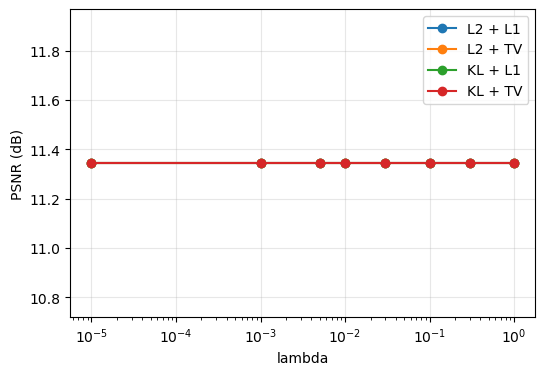

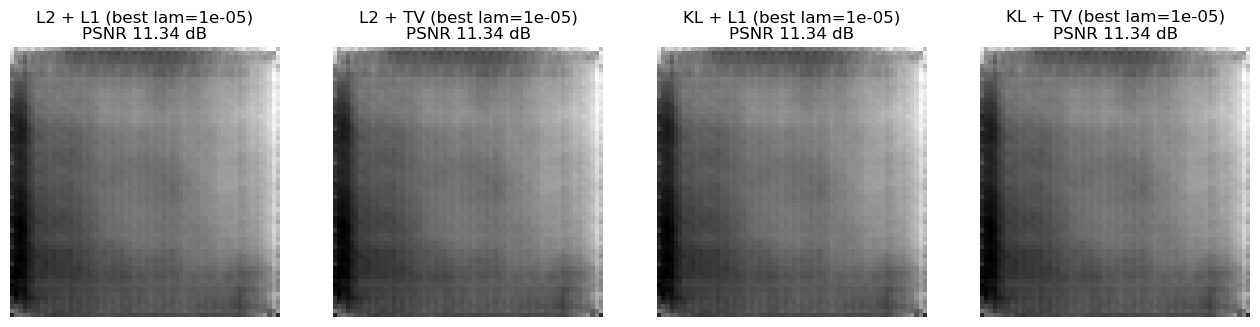

In [79]:


# ---- grid search on lambda ----
lam_grid = [0.00001, 0.001, 0.005, 0.01, 0.03, 0.1, 0.3, 1]
combos = [("L2", "L1"), ("L2", "TV"), ("KL", "L1"), ("KL", "TV")]

results = {}   # (fidelity, reg) -> PSNR for each lambda
best = {}      # (fidelity, reg) -> (best lambda, best PSNR, best reconstruction)

for fid, reg in combos:
    scores = []
    for lam in lam_grid:
        model = dinv.optim.optim_builder(
            iteration="PGD",
            prior=regularizer(REG),
            data_fidelity=data_fidelity(FIDELITY),
            params_algo={"stepsize": step, "lambda": lam, "g_param": 0.5},
            max_iter=100,
            early_stop=False,
            custom_init=lambda y, physics: {"est": ((physics.A_adjoint(y) / flux ** 2).clamp(min=0),)},
        )

        x_rec, metrics = model(y, physics, x_gt=x_true, compute_metrics=True)
        p = dinv.metric.PSNR()(x_rec, x_true).item()
        scores.append(p)
        if (fid, reg) not in best or p > best[(fid, reg)][1]:
            best[(fid, reg)] = (lam, p, x_rec)
    results[(fid, reg)] = scores

    lam_best, p_best, _ = best[(fid, reg)]
    print(f"{fid} + {reg}: best lambda = {lam_best}, PSNR = {p_best:.2f} dB")
    if lam_best in (lam_grid[0], lam_grid[-1]):
        print("   -> best lambda is at the edge of the grid: extend lam_grid on that side")

# PSNR as a function of lambda
plt.figure(figsize=(6, 4))
for (fid, reg), scores in results.items():
    plt.semilogx(lam_grid, scores, "o-", label=f"{fid} + {reg}")
plt.xlabel("lambda")
plt.ylabel("PSNR (dB)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# best reconstruction of each combination
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, ((fid, reg), (lam, p, x_rec)) in zip(ax, best.items()):
    a.imshow(x_rec.cpu().squeeze(), cmap="gray")
    a.set_title(f"{fid} + {reg} (best lam={lam})\nPSNR {p:.2f} dB")
    a.axis("off")
plt.show()